# Buổi C2: Đo mô hình phân loại, độ đúng chưa nói hết sự thật

**Hiện trường.** Phòng xét nghiệm của chị Hạnh thử một mô hình hỗ trợ **sàng lọc mẫu tế bào u**: từ 30 số đo của tế bào (kích thước nhân, độ lồi lõm...), mô hình gợi ý mẫu nào nên chuyển bác sĩ xem kỹ vì có thể là **ác tính**. Ban giám đốc hỏi một câu tưởng đơn giản: *"Mô hình đúng bao nhiêu phần trăm?"*

Chị Hạnh biết câu trả lời "96%" nghe rất đẹp, nhưng chị lo: *"Nếu 4% sai đó toàn là ca ác tính bị bỏ sót thì sao?"*

**Câu hỏi của buổi này:** *đo một mô hình phân loại thế nào cho đúng với nỗi lo của người dùng nó?*

**Mindset của người làm dữ liệu:** **một con số duy nhất không bao giờ đủ.** Việc đầu tiên là hỏi *"sai kiểu nào đau hơn?"*, rồi chọn thước đo trả lời đúng câu đó.

**Lưu ý:** dữ liệu là dữ liệu mẫu của scikit-learn để học, **không dùng để chẩn đoán**. Buổi này dùng lại cú pháp từ A1 đến C1; chỉ giải thích điều **mới**.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Độ đúng đánh lừa ta: máy lười đạt 63% |
| Chặng 2 | Ma trận nhầm lẫn và bốn thước đo: precision, recall, F1 |
| Chặng 3 | Ngưỡng: kéo thanh trượt giữa bỏ sót và báo động giả |
| Chặng 4 | Đường ROC và AUC: đo khả năng xếp hạng, bất kể ngưỡng |
| Chặng 5 | Chọn ngưỡng theo chi phí thật, không nhìn tập thi |
| Chặng 6 | Tin được đến đâu: khoảng dao động của một con số |

## Chặng 1: Độ đúng đánh lừa ta, máy lười đạt 63%

**Câu hỏi:** độ đúng (accuracy) 96% có tốt không?

Câu trả lời tùy vào **nhóm nào chiếm đa số**. Ta dựng dữ liệu và một điều **quan trọng**: chọn rõ **nhóm nào là "dương"** (positive), tức *cái ta đang đi tìm*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
bc = load_breast_cancer(as_frame=True)
X = bc.data
y = 1 - bc.target
print("sklearn's own coding: 0 =", bc.target_names[0], ", 1 =", bc.target_names[1], "-> we flip it so that 1 = malignant")
print("counts (1 = malignant):", y.value_counts().to_dict())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
lazy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("lazy machine accuracy:", round(lazy.score(X_test, y_test), 3), "| malignant caught:", int(lazy.predict(X_test)[y_test == 1].sum()), "of", int(y_test.sum()))

sklearn's own coding: 0 = malignant , 1 = benign -> we flip it so that 1 = malignant
counts (1 = malignant): {0: 357, 1: 212}
lazy machine accuracy: 0.629 | malignant caught: 0 of 53


**Giải thích từng dòng**

- `bc = load_breast_cancer(as_frame=True)`: (đã học ở A6) 569 mẫu tế bào, 30 cột số đo.
- `y = 1 - bc.target`: **quy ước quan trọng:** sklearn mã hóa *ác = 0, lành = 1*. Nhưng ta là người **đi tìm ca ác**, nên lật lại: `1 - bc.target` làm *ác = 1 (dương)*, *lành = 0 (âm)*. Từ giờ mọi thước đo (precision, recall...) mặc định tính cho nhóm **1**, nên nhóm 1 phải là *cái ta muốn tìm ra*.
- `bc.target_names[0]`: mảng tên nhóm theo mã gốc của sklearn: vị trí 0 là `malignant` (ác), vị trí 1 là `benign` (lành).
- `X_train, X_test, y_train, y_test = train_test_split(..., test_size=0.25, ..., stratify=y)`: (đã học) chia 75/25, giữ tỉ lệ ác/lành đều ở hai phần. Tập thi có 143 mẫu.
- `DummyClassifier(strategy="most_frequent")`: (đã học ở A6) máy lười luôn đoán nhóm đông nhất, tức nhóm 0 (lành).
- `int(lazy.predict(X_test)[y_test == 1].sum())`: lấy dự đoán của máy lười **chỉ ở những mẫu thật sự ác** (`[y_test == 1]` lọc theo điều kiện, đã học) rồi cộng: là số ca ác mà máy lười đoán trúng.

**Cách đọc**

- **Con số:** máy lười đạt độ đúng **63%**, nhưng bắt được **0 trên 53** ca ác. Tức là: *chưa từng báo động lần nào.*
- **Bức tranh:** nhóm lành chiếm khoảng 63% (357 trên 569 mẫu). Một máy chỉ cần luôn nói "lành" là đã "đúng" cho cả khối đa số, trong khi ca ác, thứ ta cần tìm, bị bỏ qua hoàn toàn.
- **Ý nghĩa:** độ đúng **bị đa số chi phối**. Nó trả lời "bao nhiêu ca đoán trúng", không trả lời "ca nào quan trọng đoán trúng chưa". Một mô hình đạt 96% mà nằm cạnh mốc 63% của máy lười nghe ấn tượng, nhưng ta vẫn chưa biết nó bắt ca ác tốt đến đâu.

**Mang về chặng 1:** luôn so với **mốc lười**; luôn chọn rõ **nhóm dương = cái ta đi tìm**; độ đúng một mình dễ đánh lừa khi hai nhóm lệch nhau.

## Chặng 2: Ma trận nhầm lẫn và bốn thước đo, precision, recall, F1

**Câu hỏi:** chia nhỏ "đúng" và "sai" thành các kiểu, mỗi kiểu có một cái tên.

Với mỗi mẫu có hai thông tin: **thật** là gì và **máy đoán** là gì. Hai nhóm nhân hai cách đoán cho **bốn ô**:

| | Máy đoán **ác** (dương) | Máy đoán **lành** (âm) |
|---|---|---|
| Thật sự **ác** | **TP** (true positive): bắt đúng ca ác | **FN** (false negative): **bỏ sót** ca ác |
| Thật sự **lành** | **FP** (false positive): **báo động giả** | **TN** (true negative): lành đoán lành |

Chữ cái thứ hai (P/N) là *máy đoán gì*; chữ cái thứ nhất (T/F) là *máy đúng hay sai*. Dựng mô hình rồi lập bảng:

In [3]:
from sklearn.metrics import confusion_matrix
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
pred = model.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(pd.DataFrame([[tp, fn], [fp, tn]], index=["truly malignant", "truly benign"], columns=["predicted malignant", "predicted benign"]))
print(f"TP={tp}  FN={fn}  FP={fp}  TN={tn}")

                 predicted malignant  predicted benign
truly malignant                   49                 4
truly benign                       1                89
TP=49  FN=4  FP=1  TN=89


**Giải thích từng dòng**

- `model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)`: (đã học `make_pipeline` ở B4 và C1) chuẩn hóa 30 cột rồi logistic. Pipeline lo luôn việc chuẩn hóa đúng quy tắc "học từ tập học".
- `confusion_matrix(y_test, pred).ravel()`: `confusion_matrix` trả bảng 2×2 xếp theo thứ tự nhãn 0 rồi 1: `[[TN, FP], [FN, TP]]`. `.ravel()` duỗi thành dãy bốn số theo thứ tự `TN, FP, FN, TP`, gán cho bốn biến cùng lúc.
- `pd.DataFrame([[tp, fn], [fp, tn]], index=[...], columns=[...])`: tự dựng lại bảng theo cách bày ở trên (dương ở hàng và cột đầu) để dễ đọc hơn bảng gốc của sklearn.

**Cách đọc:** trong 143 mẫu thi: bắt đúng **49** ca ác, **bỏ sót 4** ca ác, báo động giả **1** ca lành, đoán đúng lành **89** ca. Độ đúng là (49 + 89) / 143 = **96,5%**. Nhưng bảng cho thấy điều con số đó giấu: **4 ca ác bị bỏ sót**, nhiều gấp bốn lần số báo động giả (1). Với chị Hạnh, đó mới là chuyện đáng bàn.

Từ bốn ô, ta rút ra các thước đo, mỗi cái trả lời một câu hỏi khác nhau:

| Thước đo | Công thức | Câu hỏi nó trả lời |
|---|---|---|
| **Recall** (độ phủ, độ nhạy, TPR) | TP / (TP + FN) | Trong các ca ác **thật**, máy **bắt được** bao nhiêu phần? |
| **Precision** (độ chuẩn) | TP / (TP + FP) | Trong các ca máy **báo ác**, bao nhiêu phần **thật sự ác**? |
| **Specificity** (độ đặc hiệu) | TN / (TN + FP) | Trong các ca lành **thật**, máy **để yên** bao nhiêu phần? |
| **F1** | 2 × P × R / (P + R) | Một con số gộp precision và recall |

In [4]:
recall = tp / (tp + fn)
precision = tp / (tp + fp)
specificity = tn / (tn + fp)
f1 = 2 * precision * recall / (precision + recall)
print(f"recall      = {tp}/{tp + fn} = {recall:.3f}")
print(f"precision   = {tp}/{tp + fp} = {precision:.3f}")
print(f"specificity = {tn}/{tn + fp} = {specificity:.3f}")
print(f"F1          = {f1:.3f}")
from sklearn.metrics import classification_report, recall_score, precision_score, f1_score
print("\nsklearn agrees:", round(recall_score(y_test, pred), 3), round(precision_score(y_test, pred), 3), round(f1_score(y_test, pred), 3))
print(classification_report(y_test, pred, target_names=["benign (0)", "malignant (1)"], digits=3))

recall      = 49/53 = 0.925
precision   = 49/50 = 0.980
specificity = 89/90 = 0.989
F1          = 0.951

sklearn agrees: 0.925 0.98 0.951
               precision    recall  f1-score   support

   benign (0)      0.957     0.989     0.973        90
malignant (1)      0.980     0.925     0.951        53

     accuracy                          0.965       143
    macro avg      0.968     0.957     0.962       143
 weighted avg      0.966     0.965     0.965       143



**Giải thích từng dòng**

- `recall = tp / (tp + fn)`: tự tính bằng tay từ bốn ô: mẫu số `tp + fn` là **tổng số ca ác thật** (hàng trên của bảng).
- `precision = tp / (tp + fp)`: mẫu số `tp + fp` là **tổng số ca máy báo ác** (cột trái của bảng).
- `specificity = tn / (tn + fp)`: mẫu số là tổng số ca lành thật.
- `f1 = 2 * precision * recall / (precision + recall)`: **trung bình điều hòa** của precision và recall. Khác trung bình cộng ở chỗ: *nếu một trong hai thấp thì F1 thấp theo*, không che được nhau.
- `recall_score(y_test, pred), precision_score(...), f1_score(...)`: ba hàm của sklearn cho cùng kết quả; mặc định tính cho nhóm **1** (nên nhóm 1 phải là nhóm cần tìm).
- `classification_report(y_test, pred, target_names=[...], digits=3)`: **mới:** in một bảng gồm precision, recall, F1 và **support** (số mẫu thật mỗi nhóm) cho **cả hai nhóm**, cùng độ đúng chung. `target_names` đặt tên hai hàng theo thứ tự nhãn 0, 1; `digits=3` lấy ba chữ số lẻ.

**Cách đọc**

- **Con số:** recall **0,925**: máy bắt được 49 trên 53 ca ác. Precision **0,980**: trong 50 ca máy báo ác, 49 là ác thật. Specificity **0,989**. F1 **0,951**.
- **Bức tranh:** hai thước đo kể hai nỗi lo khác nhau. *Recall thấp* là nỗi lo của người bệnh: bị bỏ sót. *Precision thấp* là nỗi lo của hệ thống: báo động giả làm phí xét nghiệm và gây hoang mang. Ở đây precision (0,98) **cao hơn** recall (0,92): máy này **thận trọng khi báo ác** nhưng đang để lọt vài ca.
- **Ý nghĩa:** hàng "malignant (1)" của bảng báo cáo mới là hàng chị Hạnh cần đọc; hàng "benign" dễ đẹp vì có nhiều mẫu lành. Dòng *accuracy* là số ta bắt đầu, nhưng không còn là số quan trọng nhất.
- **Vì sao F1 dùng trung bình điều hòa?** Một máy luôn hô "ác" cho mọi ca có recall = 1 và precision khoảng 0,37; trung bình cộng cho 0,69 (nghe ổn), còn F1 cho **0,54** (phản ánh đúng là máy tệ).

**Mang về chặng 2:** đọc bốn ô TP, FP, FN, TN trước; rồi chọn thước đo theo nỗi lo. **Recall** hỏi "có bỏ sót không", **precision** hỏi "báo có đáng tin không", F1 gộp cả hai.

## Chặng 3: Ngưỡng, thanh trượt giữa bỏ sót và báo động giả

**Câu hỏi:** nếu chị Hạnh muốn *đừng bỏ sót ca ác nào*, có chỉnh được không?

Ở C1 ta đã biết `predict` chỉ là "xác suất trên 0,5 thì đoán dương". **0,5 là một lựa chọn, không phải định luật.** Hạ ngưỡng xuống 0,2 nghĩa là "chỉ cần máy ngờ ngợ 20% là báo ác": bắt nhiều hơn, nhưng cũng báo nhầm nhiều hơn.

In [5]:
proba = model.predict_proba(X_test)[:, 1]
rows = []
for t in [0.9, 0.7, 0.5, 0.3, 0.2, 0.1, 0.05]:
    guess = (proba >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, guess).ravel()
    rows.append({"threshold": t, "caught (TP)": tp_, "missed (FN)": fn_, "false alarms (FP)": fp_, "recall": tp_ / (tp_ + fn_), "precision": tp_ / (tp_ + fp_)})
table = pd.DataFrame(rows).round(3)
print(table.to_string(index=False))

 threshold  caught (TP)  missed (FN)  false alarms (FP)  recall  precision
      0.90           43           10                  0   0.811      1.000
      0.70           48            5                  0   0.906      1.000
      0.50           49            4                  1   0.925      0.980
      0.30           51            2                  1   0.962      0.981
      0.20           51            2                  3   0.962      0.944
      0.10           52            1                  6   0.981      0.897
      0.05           53            0                 11   1.000      0.828


**Giải thích từng dòng**

- `proba = model.predict_proba(X_test)[:, 1]`: (đã học) xác suất ác của từng mẫu thi.
- `for t in [0.9, 0.7, 0.5, 0.3, 0.2, 0.1, 0.05]:`: thử bảy ngưỡng từ nghiêm (0,9) đến dễ dãi (0,05).
- `guess = (proba >= t).astype(int)`: tự đoán: xác suất từ ngưỡng trở lên thì là 1 (ác). Đây chính là điều `predict` làm với `t = 0,5`.
- `confusion_matrix(y_test, guess).ravel()`: lập bảng nhầm lẫn cho từng ngưỡng; tên biến có dấu gạch dưới cuối (`tn_`) để không đè lên `tn`, `fp`... của chặng 2.
- `rows.append({...})`: (đã học) gom mỗi ngưỡng thành một dòng (từ điển) để cuối cùng dựng bảng.

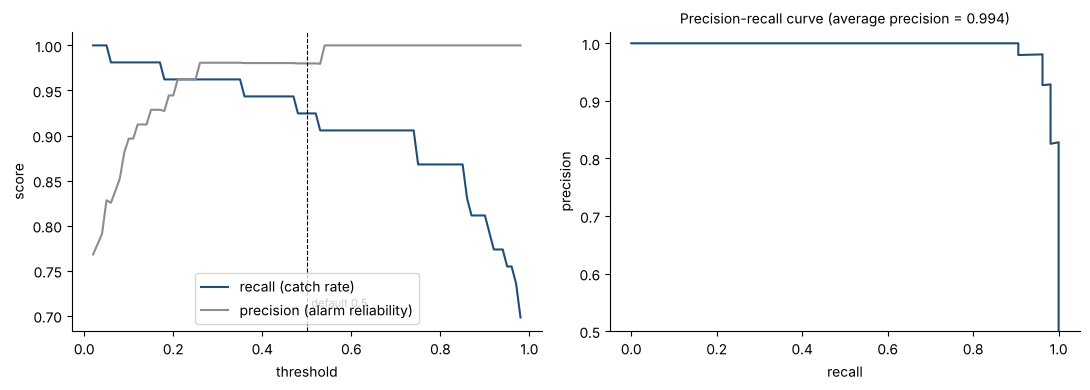

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ts = np.linspace(0.02, 0.98, 97)
recalls, precisions = [], []
for t in ts:
    guess = (proba >= t).astype(int)
    recalls.append(recall_score(y_test, guess)); precisions.append(precision_score(y_test, guess, zero_division=1))
ax[0].plot(ts, recalls, color=BLUE, label="recall (catch rate)")
ax[0].plot(ts, precisions, color=GRAY, label="precision (alarm reliability)")
ax[0].axvline(0.5, color="black", linestyle="--", linewidth=0.8); ax[0].text(0.51, 0.71, "default 0.5", fontsize=8)
ax[0].set_xlabel("threshold"); ax[0].set_ylabel("score"); ax[0].legend(loc="lower center")
from sklearn.metrics import precision_recall_curve, average_precision_score
pr_p, pr_r, _ = precision_recall_curve(y_test, proba)
ax[1].plot(pr_r, pr_p, color=BLUE)
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_ylim(0.5, 1.02)
ax[1].set_title(f"Precision-recall curve (average precision = {average_precision_score(y_test, proba):.3f})", fontsize=10)
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `ts = np.linspace(0.02, 0.98, 97)`: 97 ngưỡng sát nhau để đường mượt.
- `precision_score(y_test, guess, zero_division=1)`: tùy chọn mới: nếu ở ngưỡng quá cao mà máy **không báo ca nào**, precision có mẫu số 0; `zero_division=1` quy ước giá trị 1 thay vì báo lỗi.
- `ax[0].axvline(0.5, ...)`: vạch đứt đánh dấu ngưỡng mặc định.
- `precision_recall_curve(y_test, proba)`: **mới:** hàm tự quét mọi ngưỡng và trả ba mảng: precision, recall và danh sách ngưỡng (ta bỏ qua cái thứ ba bằng `_`). Vẽ precision theo recall cho **đường PR**.
- `average_precision_score(y_test, proba)`: một con số tóm tắt đường PR (diện tích dưới đường theo kiểu bậc thang): càng gần 1 càng tốt.

**Cách đọc**

- **Con số:** ở ngưỡng 0,5: bỏ sót 4, báo giả 1. Hạ xuống 0,2: bỏ sót **2**, báo giả **3**. Hạ xuống 0,05: bỏ sót **0** (không sót ca nào) nhưng báo giả **11**.
- **Bức tranh (hình trái):** đường xanh (recall) **đi lên** khi ngưỡng giảm sang trái; đường xám (precision) **đi xuống** theo chiều đó. Hai đường *không thể cùng cao mãi*: kéo thanh trượt về phía nào thì được phía đó, mất phía kia. **Hình phải** là cùng câu chuyện vẽ theo cách khác: đi từ recall thấp (precision tuyệt đối 1) sang recall 1 (precision tụt).
- **Ý nghĩa:** "độ đúng của mô hình" thật ra là **độ đúng của mô hình *tại một ngưỡng***. Cái ngưỡng đó là quyết định của người dùng mô hình (cân nhắc chi phí, chặng 5), không phải của máy.

**Mang về chặng 3:** hạ ngưỡng thì bắt nhiều hơn (recall lên) nhưng báo giả nhiều hơn (precision xuống). Ngưỡng 0,5 chỉ là mặc định.

## Chặng 4: Đường ROC và AUC, đo khả năng xếp hạng bất kể ngưỡng

**Câu hỏi:** có cách đánh giá một mô hình *không phụ thuộc* vào ngưỡng đã chọn không?

Đường **ROC** vẽ **mọi ngưỡng** cùng lúc, với hai trục:

- Trục dọc: **TPR** = recall = tỉ lệ ca ác thật được bắt.
- Trục ngang: **FPR** = FP / (FP + TN) = tỉ lệ ca lành thật bị báo nhầm (bằng 1 − specificity).

Mỗi ngưỡng cho một điểm; nối lại thành đường. Ngưỡng cao ở góc dưới trái (không báo gì), ngưỡng thấp ở góc trên phải (báo hết).

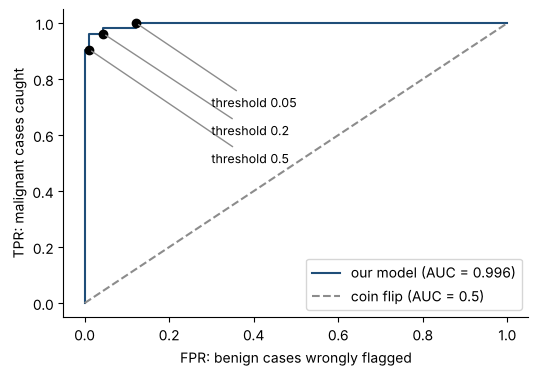

AUC = 0.9962


In [7]:
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, thr = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)
plt.plot(fpr, tpr, color=BLUE, label=f"our model (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], color=GRAY, linestyle="--", label="coin flip (AUC = 0.5)")
for i, t in enumerate([0.5, 0.2, 0.05]):
    k = np.argmin(np.abs(thr - t))
    plt.plot(fpr[k], tpr[k], "o", color="black")
    plt.annotate(f"threshold {t}", (fpr[k], tpr[k]), xytext=(0.3, 0.5 + 0.1 * i), fontsize=9, arrowprops=dict(arrowstyle="-", color=GRAY))
plt.xlabel("FPR: benign cases wrongly flagged"); plt.ylabel("TPR: malignant cases caught")
plt.legend(loc="lower right"); plt.show()
print("AUC =", round(auc, 4))

**Giải thích từng dòng**

- `fpr, tpr, thr = roc_curve(y_test, proba)`: **mới:** quét mọi ngưỡng, trả ba mảng: FPR, TPR và các ngưỡng tương ứng. Đưa **xác suất**, không phải nhãn.
- `auc = roc_auc_score(y_test, proba)`: **AUC** (area under curve) là **diện tích dưới đường ROC**, từ 0 đến 1.
- `plt.plot([0, 1], [0, 1], color=GRAY, linestyle="--", ...)`: đường chéo là *máy tung đồng xu*: bắt được bao nhiêu thì báo giả bấy nhiêu.
- `k = np.argmin(np.abs(thr - t))`: (đã học `argmin` ở B6) tìm vị trí của ngưỡng gần nhất với `t` trong danh sách ngưỡng của `roc_curve`; `np.abs` là trị tuyệt đối.
- `plt.plot(fpr[k], tpr[k], "o", ...)`: chấm tròn đánh dấu ba ngưỡng quen thuộc lên đường.
- `plt.annotate(f"threshold {t}", (fpr[k], tpr[k]), xytext=(0.3, ...), arrowprops=...)`: **mới:** `annotate` viết chữ ở vị trí `xytext` và **vẽ mũi tên (ở đây chỉ là đường nối)** tới điểm cần chú thích: ba nhãn được xếp thẳng hàng bên phải thay vì chen sát nhau quanh các điểm.

**Cách đọc**

- **Con số:** AUC = **0,996**. Ở ngưỡng 0,5 điểm nằm ở khoảng (FPR 0,01; TPR 0,92); ở ngưỡng 0,05 điểm nằm ở khoảng (FPR 0,12; TPR 1,0).
- **Bức tranh:** đường xanh **bay vọt lên sát góc trên bên trái** rồi chạy ngang gần mép trên: nghĩa là bắt được gần hết ca ác mà báo nhầm rất ít. Đường chéo đứt là mốc tung đồng xu; đường càng *phồng về góc trên trái* càng giỏi.
- **Ý nghĩa của AUC (một cách hiểu đời thường):** lấy ngẫu nhiên **một ca ác và một ca lành**; AUC là *xác suất máy cho ca ác điểm cao hơn ca lành*. AUC = 0,5 là xếp hạng ngẫu nhiên; AUC = 1 là xếp hạng hoàn hảo. Ta kiểm chứng ngay bằng cách đếm tất cả các cặp:

In [8]:
score_malignant = proba[(y_test == 1).values]
score_benign = proba[(y_test == 0).values]
wins = (score_malignant[:, None] > score_benign[None, :]).mean()
ties = (score_malignant[:, None] == score_benign[None, :]).mean()
print(f"{len(score_malignant)} malignant x {len(score_benign)} benign = {len(score_malignant) * len(score_benign)} pairs")
print(f"share of pairs where the malignant case gets the higher score = {wins + 0.5 * ties:.4f}   (AUC = {auc:.4f})")

53 malignant x 90 benign = 4770 pairs
share of pairs where the malignant case gets the higher score = 0.9962   (AUC = 0.9962)


**Giải thích từng dòng**

- `score_malignant = proba[(y_test == 1).values]`: lấy điểm của riêng các ca ác thật. `.values` đổi cột pandas thành mảng numpy để lọc theo Đúng/Sai.
- `score_malignant[:, None] > score_benign[None, :]`: **mới:** `[:, None]` biến dãy thành *một cột dọc* và `[None, :]` biến dãy kia thành *một hàng ngang*; so sánh `>` giữa chúng cho **bảng mọi cặp** (mỗi ca ác với mỗi ca lành): Đúng nếu ca ác có điểm cao hơn.
- `.mean()`: (đã học) trung bình của Đúng/Sai chính là **tỉ lệ cặp** mà ca ác thắng.
- `wins + 0.5 * ties`: cặp bằng điểm nhau tính nửa thắng, theo quy ước của AUC.

**Cách đọc:** tỉ lệ cặp "ca ác được điểm cao hơn ca lành" đúng bằng AUC (**0,9962**). Không có phép màu: AUC chỉ là *chất lượng xếp hạng*, ngưỡng chưa dính vào.

**Hai lời cảnh báo.** AUC rất cao (0,99+) không có nghĩa mô hình *ở ngưỡng bạn chọn* đã đủ tốt: nó chỉ nói rằng *có tồn tại* một ngưỡng tốt. Và khi nhóm dương **hiếm** (ví dụ 1%), AUC dễ đẹp giả tạo vì FPR được chia cho một số rất lớn các ca lành; khi ấy nên nhìn **đường PR** (chặng 3) và sẽ gặp lại ở buổi C8.

**Mang về chặng 4:** ROC vẽ mọi ngưỡng; **AUC** là xác suất xếp ca dương cao hơn ca âm. Nó đo *khả năng xếp hạng*, không đo *chất lượng ở một ngưỡng cụ thể*.

## Chặng 5: Chọn ngưỡng theo chi phí thật, không nhìn tập thi

**Câu hỏi:** vậy chị Hạnh chọn ngưỡng nào, và dựa vào đâu?

Dựa vào **chi phí của từng kiểu sai**, thứ mà ban giám đốc (không phải máy) biết. Giả sử họ ước tính: **bỏ sót một ca ác đau gấp 20 lần một báo động giả** (một ca nữa là mất cơ hội điều trị sớm, còn báo giả chỉ tốn thêm một lần xét nghiệm). Khi đó:

**chi phí = 20 × FN + 1 × FP**

Quy tắc vàng: **chọn ngưỡng trên dữ liệu học, KHÔNG trên tập thi**. Nhưng nếu chọn ngay trên tập học, máy đã nhìn chính những ca đó nên điểm đẹp quá mức. Giải pháp là `cross_val_predict`: dự đoán cho từng mẫu của tập học bằng một mô hình **chưa từng thấy mẫu đó** (kiểm định chéo).

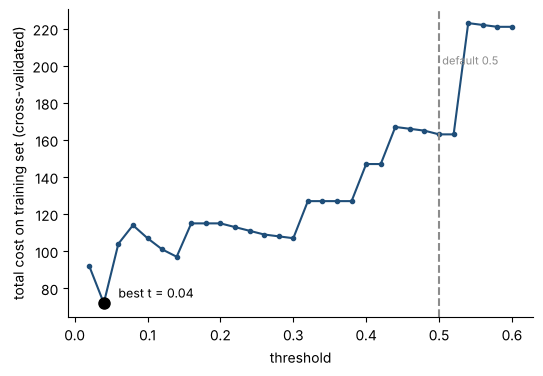

best threshold: 0.04 | cost there: 72 | cost at 0.5: 163


In [9]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
proba_cv = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
COST_MISS, COST_ALARM = 20, 1
def cost_at(t, truth, p):
    guess = (p >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(truth, guess).ravel()
    return COST_MISS * fn_ + COST_ALARM * fp_
ts = np.round(np.arange(0.02, 0.62, 0.02), 2)
costs_cv = np.array([cost_at(t, y_train, proba_cv) for t in ts])
best_t = ts[costs_cv.argmin()]
plt.plot(ts, costs_cv, "o-", color=BLUE, markersize=3)
plt.plot(best_t, costs_cv.min(), "o", color="black", markersize=8); plt.text(best_t + 0.02, costs_cv.min() + 3, f"best t = {best_t}", fontsize=9)
plt.axvline(0.5, color=GRAY, linestyle="--"); plt.text(0.5, costs_cv.max() * 0.9, " default 0.5", fontsize=8, color=GRAY)
plt.xlabel("threshold"); plt.ylabel("total cost on training set (cross-validated)")
plt.show()
print("best threshold:", best_t, "| cost there:", costs_cv.min(), "| cost at 0.5:", cost_at(0.5, y_train, proba_cv))

**Giải thích từng dòng**

- `from sklearn.model_selection import cross_val_predict, StratifiedKFold`: **mới:** `cross_val_predict` và bản chia phân tầng `StratifiedKFold`.
- `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)`: chia tập học thành 5 phần giữ tỉ lệ ác/lành; `shuffle=True` xáo trước khi chia.
- `cross_val_predict(..., cv=cv, method="predict_proba")[:, 1]`: **mới:** với mỗi phần, học trên 4 phần còn lại rồi **đoán cho phần đó**; ghép lại thành dự đoán cho **mọi** mẫu tập học mà không mẫu nào được đoán bởi mô hình đã thấy nó. `method="predict_proba"` xin xác suất thay vì nhãn.
- `COST_MISS, COST_ALARM = 20, 1`: viết hoa tên biến là thói quen cho **hằng số** (con số cài đặt do người dùng chọn, không đổi trong bài). Đây là chỗ ban giám đốc nhập giá trị của họ.
- `def cost_at(t, truth, p):`: hàm tính tổng chi phí ở ngưỡng `t`: `20 × FN + 1 × FP`.
- `best_t = ts[costs_cv.argmin()]`: (đã học `argmin`) ngưỡng cho chi phí thấp nhất.

**Cách đọc**

- **Con số:** trên tập học (kiểm định chéo), ngưỡng 0,5 cho chi phí **163**; ngưỡng tốt nhất **0,04** chỉ **72**, chưa đến một nửa.
- **Bức tranh:** đường chi phí **gập ghềnh**, có đáy nằm rất bên trái (ngưỡng 0,04), rồi **leo dần lên** khi ngưỡng tăng, và nhảy vọt quanh ngưỡng 0,5 (vạch đứt) vì lúc đó nhiều ca ác bị bỏ sót, mỗi ca phạt 20. Sát mép trái hơn nữa (0,02) chi phí tăng lại vì báo giả bùng nổ.
- **Cẩn thận:** đáy là ngưỡng 0,04 với chi phí 72, nhưng các ngưỡng lân cận đắt hơn đáng kể (0,02 cho 92; 0,06 cho 104): đường nhiễu vì tập học cũng chỉ có 159 ca ác. Kết luận chắc chắn là *"ngưỡng nên rất thấp, dưới 0,1"*, không phải con số 0,04 chính xác từng ly.
- **Ý nghĩa:** khi chi phí hai kiểu sai khác nhau, ngưỡng tối ưu **không bao giờ là 0,5**. Con số 20 là của ban giám đốc; đổi nó thành 5 hay 100 thì ngưỡng đổi theo.

Giờ **mở tập thi đúng một lần** để xem ngưỡng đã chọn có giữ được hiệu quả không:

In [10]:
for t in [0.5, best_t]:
    guess = (proba >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, guess).ravel()
    print(f"threshold {t:<5}: missed {fn_}, false alarms {fp_}, cost = {COST_MISS * fn_ + COST_ALARM * fp_:>3}, recall = {tp_ / (tp_ + fn_):.3f}, precision = {tp_ / (tp_ + fp_):.3f}")

threshold 0.5  : missed 4, false alarms 1, cost =  81, recall = 0.925, precision = 0.980
threshold 0.04 : missed 0, false alarms 14, cost =  14, recall = 1.000, precision = 0.791


**Giải thích từng dòng**

- `for t in [0.5, best_t]:`: so hai ngưỡng: mặc định và ngưỡng đã chọn *từ tập học*.
- `f"threshold {t:<5}: ..."`: `:<5` canh trái trong 5 ký tự; `:>3` canh phải trong 3 ký tự: để các dòng thẳng cột.

**Cách đọc:** trên tập thi, ngưỡng 0,5 cho chi phí **81** (4 ca sót, 1 báo giả); ngưỡng 0,04 cho chi phí **14** (không sót ca nào, đổi lại 14 báo giả). Đúng như mong đợi, nhưng nhớ rằng tập thi chỉ có **53 ca ác**: một ca sót hay không đổi chi phí 20 điểm. Hiệu quả thật sự của ngưỡng mới *có thể* khác; ta chỉ chắc rằng hướng đi (hạ ngưỡng) hợp lý.

**Mang về chặng 5:** chọn ngưỡng bằng **chi phí** do người dùng quyết; tìm ngưỡng **trên tập học bằng `cross_val_predict`**; chỉ mở tập thi một lần để kiểm tra.

## Chặng 6: Tin được đến đâu, khoảng dao động của một con số

**Câu hỏi:** recall 0,92 có nghĩa mô hình bắt được 92% ca ác thật không?

Chưa chắc. Con số đó đo trên **53 ca ác**. Nếu chị Hạnh có một bộ 53 ca *khác*, recall có thể là 0,89 hay 0,96. Ta có thể ước lượng độ dao động bằng cách **chơi lại việc lấy mẫu**: bốc ngẫu nhiên 143 mẫu *có hoàn lại* từ tập thi (một kỹ thuật tên **bootstrap**), tính recall, lặp 2000 lần.

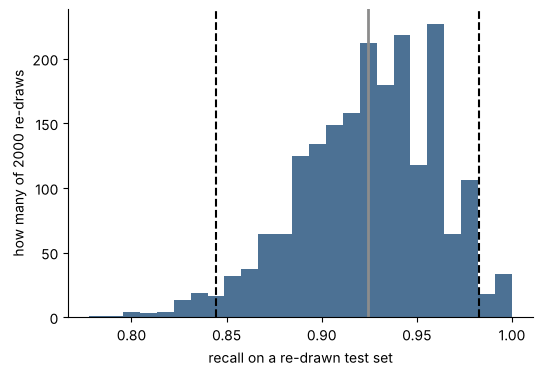

recall observed = 0.925 | 95% of re-draws fall between 0.844 and 0.982


In [11]:
rng = np.random.default_rng(0)
truth = y_test.values
boot_recall = []
for _ in range(2000):
    pick = rng.choice(len(truth), size=len(truth), replace=True)
    boot_recall.append(recall_score(truth[pick], pred[pick]))
low, high = np.percentile(boot_recall, [2.5, 97.5])
plt.hist(boot_recall, bins=25, color=BLUE, alpha=0.8)
plt.axvline(low, color="black", linestyle="--"); plt.axvline(high, color="black", linestyle="--")
plt.axvline(recall, color=GRAY, linewidth=2)
plt.xlabel("recall on a re-drawn test set"); plt.ylabel("how many of 2000 re-draws")
plt.show()
print(f"recall observed = {recall:.3f} | 95% of re-draws fall between {low:.3f} and {high:.3f}")

**Giải thích từng dòng**

- `rng = np.random.default_rng(0)`: (đã gặp ở C1) bộ sinh số ngẫu nhiên với hạt giống 0.
- `truth = y_test.values`: đáp án thật dạng mảng numpy để chọn theo vị trí.
- `pick = rng.choice(len(truth), size=len(truth), replace=True)`: **mới:** bốc ngẫu nhiên 143 *vị trí* từ 0 đến 142, **có hoàn lại** (`replace=True`): một mẫu có thể xuất hiện hai ba lần, mẫu khác không xuất hiện. Đó là cách giả lập "một tập thi khác" từ chính tập thi đang có.
- `recall_score(truth[pick], pred[pick])`: tính recall trên tập thi vừa bốc; `truth[pick]` lấy đáp án theo vị trí đã bốc.
- `np.percentile(boot_recall, [2.5, 97.5])`: **mới:** `np.percentile` cho giá trị mà 2,5% kết quả nằm dưới và 97,5% nằm dưới: hai mốc cắt **95% ở giữa**. Đây là **khoảng 95%**.

**Cách đọc**

- **Con số:** recall quan sát được **0,925**, nhưng 95% các lần bốc lại cho recall từ **0,84** đến **0,98**.
- **Bức tranh:** đống cột hình chuông **trải khá rộng**, lệch trái (không thể vượt 1 nên đuôi phải bị chặn, đuôi trái dài). Vạch xám là con số quan sát được, hai vạch đen là rìa khoảng 95%.
- **Ý nghĩa:** với chỉ 53 ca ác, "recall 0,92" thật ra nghĩa là *"khoảng từ 0,84 đến 0,98"*. Đừng so hai mô hình chỉ vì recall chênh 0,02: khoảng dao động lớn hơn nhiều. Muốn con số chắc hơn cần **nhiều ca ác hơn** hoặc **lặp kiểm định chéo** (như B6, C1).

## Phán quyết và bài học nghề

**Phán quyết cho chị Hạnh.**

- **Trả lời ban giám đốc đừng chỉ nói "96,5%".** Nói: *"Trên 143 mẫu thi, mô hình bắt 49 trên 53 ca ác (recall 0,92, dao động khoảng 0,84 đến 0,98) và báo nhầm 1 trong 90 ca lành."*
- **Nếu bỏ sót đau gấp 20 lần báo giả**, hạ ngưỡng xuống khoảng 0,04: bắt hết ca ác trên tập thi, đổi lại thêm khoảng chục ca báo giả để bác sĩ xem lại.
- **Mô hình chỉ là bộ lọc hỗ trợ**: mọi ca được báo ác phải qua bác sĩ.

**Bài học nghề.**

1. **Độ đúng bị nhóm đa số chi phối**; luôn so với **máy lười**.
2. **Chọn nhóm dương = cái ta đi tìm**, rồi đọc **bốn ô TP, FP, FN, TN**.
3. **Recall** hỏi "có bỏ sót không", **precision** hỏi "báo có đáng tin không", **F1** gộp hai (trung bình điều hòa).
4. **Ngưỡng là quyết định của người dùng**: chọn theo chi phí, trên **dữ liệu học** (`cross_val_predict`), không nhìn tập thi.
5. **ROC/AUC** đo khả năng *xếp hạng* bất kể ngưỡng; nhóm dương hiếm thì nhìn **đường PR**.
6. **Mọi con số đo trên tập thi nhỏ đều có khoảng dao động**; nói cả khoảng, không chỉ nói điểm.

**Một điều thành thật:** chi phí 20:1 trong buổi này là **giả định minh họa**. Trong thực tế đó là một con số phải bàn với bác sĩ và ban giám đốc; máy không tự biết.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Độ đúng bị nhóm đa số chi phối: máy lười đạt 63% mà không bắt ca ác nào. |
| 2 | Chọn nhóm dương là cái ta đi tìm; đọc bốn ô TP, FP, FN, TN; recall, precision, specificity, F1. |
| 3 | Ngưỡng là thanh trượt giữa bỏ sót và báo giả; 0,5 chỉ là mặc định. |
| 4 | ROC vẽ mọi ngưỡng; AUC là xác suất ca dương được điểm cao hơn ca âm. |
| 5 | Chọn ngưỡng theo chi phí do người dùng quyết, bằng `cross_val_predict` trên tập học. |
| 6 | Con số trên tập thi nhỏ có khoảng dao động rộng; dùng bootstrap để nói cả khoảng. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Ca ác được bắt đúng | true positive (TP) | `tp` |
| Ca ác bị bỏ sót | false negative (FN) | `fn` |
| Báo ác nhầm cho ca lành | false positive (FP) | `fp` |
| Trong ca ác thật, bắt được bao nhiêu | recall (độ nhạy, TPR) | `recall_score` |
| Trong ca báo ác, đúng bao nhiêu | precision | `precision_score` |
| Một số gộp precision và recall | F1 | `f1_score` |
| Bảng nhiều thước đo cho cả hai nhóm | báo cáo phân loại | `classification_report` |
| Đường mọi ngưỡng, diện tích dưới đường | ROC, AUC | `roc_curve`, `roc_auc_score` |
| Đường precision theo recall | đường PR | `precision_recall_curve` |
| Đoán cho mỗi mẫu bằng mô hình chưa thấy mẫu đó | dự đoán kiểm định chéo | `cross_val_predict` |
| Bốc lại có hoàn lại để ước lượng dao động | bootstrap | `rng.choice(..., replace=True)` |

**Thử thách tự làm**

1. Ở chặng 5, đổi `COST_MISS` thành 5 rồi 100. Ngưỡng tối ưu dịch chuyển thế nào? Vì sao?
2. Đổi nhóm dương: dùng `y = bc.target` (lành = 1) mà không lật. Chạy lại chặng 2 và so sánh recall, precision. Vì sao hai con số "đổi chỗ" như vậy?
3. Kể chuyện với dữ liệu khác: dùng chị Mai ở C1 (hai loài iris). Coi virginica là nhóm dương, vẽ đường ROC và tính AUC. So với đường ROC của ung thư vú, đường nào phồng hơn? Vì sao?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích vì sao độ đúng có thể đánh lừa, và nêu ví dụ máy lười.
- [ ] Đọc được bốn ô TP, FP, FN, TN và tính tay recall, precision, F1.
- [ ] Giải thích ngưỡng ảnh hưởng thế nào đến bỏ sót và báo giả.
- [ ] Hiểu đường ROC và nói được AUC bằng lời đời thường.
- [ ] Chọn ngưỡng theo chi phí trên dữ liệu học, không dùng tập thi.
- [ ] Biết một con số trên tập thi nhỏ có khoảng dao động.

## Phần thưởng (Tip pro): Macro, micro và weighted: khi có nhiều hơn hai nhóm


Khi bài có **nhiều nhóm** (buổi C7), recall, precision, F1 được tính cho từng nhóm rồi phải **gộp** lại. Ba cách gộp trong `f1_score(..., average=...)`: `"macro"` lấy **trung bình đều** các nhóm (nhóm hiếm có tiếng nói ngang nhóm đông); `"weighted"` lấy trung bình **có trọng số theo số mẫu** (nhóm đông nói to hơn); `"micro"` gộp mọi mẫu lại rồi tính một lần (với bài đơn nhãn nó bằng độ đúng). Muốn công bằng với nhóm hiếm thì nhìn **macro**.

In [12]:
print("F1 macro   :", round(f1_score(y_test, pred, average="macro"), 3), "(average of the two classes' F1)")
print("F1 weighted:", round(f1_score(y_test, pred, average="weighted"), 3), "(weighted by class size)")
print("F1 micro   :", round(f1_score(y_test, pred, average="micro"), 3), "(= accuracy for single-label problems)")

F1 macro   : 0.962 (average of the two classes' F1)
F1 weighted: 0.965 (weighted by class size)
F1 micro   : 0.965 (= accuracy for single-label problems)


**Giải thích từng dòng**

- `f1_score(y_test, pred, average="macro")`: trung bình đều F1 của nhóm lành và nhóm ác.
- `average="weighted"`: trung bình có trọng số theo số mẫu mỗi nhóm.
- `average="micro"`: gộp mọi mẫu trước khi tính: bài hai nhóm một nhãn thì bằng độ đúng.